# Un factor de roca que no usa nada del sitio objetivo, y cuánto del puntaje clásico era prestado

**Nivel 4: Más allá del estado del arte** · Requiere: 02-classical-prediction/02-the-rock-factor, 02-classical-prediction/03-the-published-hold-out-tables · Tiempo de lectura: unos 30 minutos

## Objetivos

El predictor clásico de los notebooks anteriores lee un factor de roca que se recuperó de las predicciones publicadas del mismo sitio en que se puntúa. Con el sitio fuera, eso equivale a usar conocimiento del propio sitio excluido, que un predictor aprendido nunca recibe. Este notebook mide cuánto aporta ese conocimiento al puntaje clásico, reemplazando la constante del sitio por un factor predicho desde el módulo de Young de la roca usando solo los otros sitios (afirmación BS-4).

Al terminar, usted habrá:

- ajustado la relación log-lineal entre los factores recuperados y los módulos de los sitios y comparado con el ajuste versionado;
- puntuado el predictor de constante de sitio y el predictor de transferencia con un sitio fuera y con un intervalo con remuestreo de sitios, y comprobado que los resultados coinciden con el benchmark versionado;
- leído, sitio por sitio, el factor que predice el predictor de transferencia frente al factor recuperado del artículo.

## Preparación

Instale los paquetes con las versiones exactas de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

Esta celda aún no importa nada del notebook: lee las versiones instaladas desde los metadatos de los paquetes y las imprime, de modo que la salida registra qué motor produjo cada número que sigue.

In [1]:
# Imprima la versión instalada de cada paquete que usa este notebook
from importlib.metadata import version

for name in ("blastfrag", "numpy", "matplotlib",):
    print(f"{name}=={version(name)}")

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Los 97 tiros, sus módulos y los factores por sitio recuperados | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957; Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 | hechos numéricos reutilizados con cita; los artículos nunca se distribuyen | el corpus y `bf.SITE_ROCK_FACTOR` dentro del paquete `blastfrag` |
| El ajuste versionado y los puntajes versionados con un sitio fuera | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/benchmark.json`, campos `diagnostics.transfer_fit` y `protocols` |

## Método

El predictor de transferencia ajusta una recta en logaritmos sobre los sitios de entrenamiento,

```
ln A = a + b * ln E
```

con un punto por sitio (el factor recuperado del sitio contra su módulo medio), de modo que una cantera de 22 tiros y una mina de seis pesan lo mismo. El factor de un tiro es entonces `exp(a + b ln E)`, calculado a partir de su propio módulo, dato que un ingeniero tiene antes del primer tiro en una mina nueva. La relación es una calibración del motor, no una ecuación publicada. Con un sitio fuera la recta se reajusta sin el sitio excluido en cada pliegue.

El intervalo es un bootstrap que remuestrea **sitios**, no tiros, porque las filas de una campaña no son observaciones independientes (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

## Estado del arte

- Los dos artículos de origen (Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957; Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3) declaran que el factor de roca se estimó para cada tiro y no imprimen ningún valor. Los factores recuperados de sus predicciones se comportan como una constante por sitio (notebook 02 de este tema: una dispersión de unos pocos por ciento dentro de un sitio).
- Cualquier evaluación de la ecuación clásica que use esos factores en el mismo sitio le da a la ecuación un número ajustado al sitio, y la base de investigación del SDD anota que los estudios publicados de predictores aprendidos no dejan fuera una mina completa. Un puntaje con un sitio fuera calculado así no puede separar la habilidad de la ecuación del origen del factor.
- Remuestrear la unidad correcta importa: una validación cruzada que ignora la dependencia de los datos puede subestimar seriamente el error de predicción (Roberts et al. 2017, https://doi.org/10.1111/ecog.02881).

## Más allá del estado del arte

### Paso 1: ajustar la relación en todos los sitios

La celda ajusta `KuznetsovTransfer` en todo el corpus, imprime su intercepto y su pendiente junto al ajuste versionado, y calcula la correlación entre los módulos de los sitios y los factores recuperados, en logaritmos.

ajustado aquí:  intercept = 0.384106  slope = 0.502909
versionado:      intercept = 0.384106  slope = 0.502909
mismos sitios: True
correlación de ln A con ln E sobre los sitios = 0.891


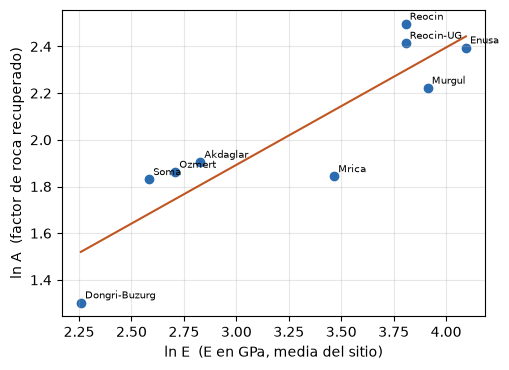

In [2]:
# Importaciones, y luego el ajuste sobre los nueve sitios con factor recuperado, contra el ajuste versionado
import json
from pathlib import Path

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
benchmark = json.loads((DERIVED / "benchmark.json").read_text(encoding="utf-8"))
committed = benchmark["diagnostics"]["transfer_fit"]
transfer = bf.KuznetsovTransfer().fit(train)
print(f"ajustado aquí:  intercept = {transfer.intercept:.6f}  slope = {transfer.slope:.6f}")
print(f"versionado:      intercept = {committed['intercept']:.6f}  slope = {committed['slope']:.6f}")
print("mismos sitios:", list(transfer.fit_sites) == committed["fit_sites"])

sites = list(transfer.fit_sites)
log_e = np.log([np.mean([b.E_GPa for b in train if b.site == s]) for s in sites])
log_a = np.log([bf.SITE_ROCK_FACTOR[s] for s in sites])
print(f"correlación de ln A con ln E sobre los sitios = {np.corrcoef(log_e, log_a)[0, 1]:.3f}")

fig, ax = plt.subplots(figsize=(5.2, 3.8))
ax.scatter(log_e, log_a, color="#2b6cb0")
for s, x, y in zip(sites, log_e, log_a):
    ax.annotate(s, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")
grid = np.linspace(log_e.min(), log_e.max(), 20)
ax.plot(grid, transfer.intercept + transfer.slope * grid, color="#c05621")
ax.set_xlabel("ln E  (E en GPa, media del sitio)")
ax.set_ylabel("ln A  (factor de roca recuperado)")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

### Paso 2: un sitio fuera, dos veces

Para cada uno de los diez sitios la celda entrena con los otros nueve, predice el sitio excluido con el predictor de constante de sitio y con el de transferencia, y registra el factor que usó el de transferencia. Miami no tiene geometría, así que ambos predictores se abstienen allí. La recta del predictor de transferencia se reajusta sin el sitio excluido en cada pliegue.

In [3]:
# Un sitio fuera para los dos predictores clásicos, guardando el factor que el predictor de transferencia predijo para cada sitio
tested, predictions, factors = [], {"kuznetsov": [], "kuznetsov-transfer": [], "null": []}, {}
for split in bf.leave_one_site_out(train):
    site = split.detail["held_out_site"]
    site_constant = bf.Kuznetsov().fit(split.train)
    transferred = bf.KuznetsovTransfer().fit(split.train)
    predictions["kuznetsov"] += site_constant.predict(split.test)
    predictions["kuznetsov-transfer"] += transferred.predict(split.test)
    predictions["null"] += bf.NullModel().fit(split.train).predict(split.test)
    tested += list(split.test)
    factors[site] = transferred.rock_factor_for(float(np.mean([b.E_GPa for b in split.test])))
print(f"{'sitio excluido':<16}{'A recuperado':>16}{'A predicho (solo otros sitios)':>38}")
for site, predicted in factors.items():
    recovered = bf.SITE_ROCK_FACTOR.get(site)
    print(f"{site:<16}" + (f"{recovered:>16.2f}" if recovered else f"{'-':>16}") + f"{predicted:>38.2f}")

sitio excluido      A recuperado        A predicho (solo otros sitios)
Akdaglar                    6.72                                  5.97
Dongri-Buzurg               3.68                                  5.25
Enusa                      10.97                                 11.74
Miami                          -                                  4.67
Mrica                       6.32                                  8.72
Murgul                      9.23                                 10.89
Ozmert                      6.44                                  5.57
Reocin                     12.14                                  9.51
Reocin-UG                  11.19                                  9.69
Soma                        6.24                                  5.14


### Paso 3: puntuar ambos predictores, con un intervalo con remuestreo de sitios, contra el benchmark versionado

Ambos predictores clásicos se puntúan sobre los 91 tiros con geometría resoluble. El intervalo remuestrea sitios 2000 veces con la semilla del benchmark, de modo que el resultado sea exactamente comparable con el versionado. El modelo nulo, que predice la media de los sitios de entrenamiento, se puntúa sobre las mismas filas como referencia.

In [4]:
# Puntuar cada predictor sobre las filas que responde, con un intervalo de 95 por ciento con remuestreo de sitios, y comparar con los valores versionados
loso = benchmark["protocols"]["leave-one-site-out"]["arms"]
print(f"{'predictor':<22}{'n':>4}{'r2 identidad':>14}{'intervalo 95 %':>26}  igual a versionado")
for name, predicted in predictions.items():
    answered = [(b, p) for b, p in zip(tested, predicted) if p.x50_m is not None and bf.has_absolute_geometry(b)]
    rows, preds = [a[0] for a in answered], [a[1] for a in answered]
    point, low, high = bf.bootstrap_interval(rows, preds, "r2_identity", n_boot=2000, unit="site", seed=0)
    want = loso[name]["supports"]["geometry"]
    same = abs(point - want["score"]["r2_identity"]) < 1e-9 and abs(low - want["interval_95"][0]) < 1e-9 and abs(high - want["interval_95"][1]) < 1e-9
    print(f"{name:<22}{len(rows):>4}{point:>14.4f}{f'{low:.3f} a {high:.3f}':>26}  {same}")
    if name == "null":
        print("(el nulo predice la media de los otros sitios, reajustada en cada pliegue)")

predictor                n  r2 identidad            intervalo 95 %  igual a versionado
kuznetsov               91        0.3112            -0.966 a 0.686  True
kuznetsov-transfer      91        0.2982            -1.097 a 0.708  True
null                    91       -0.2320           -1.330 a -0.158  True
(el nulo predice la media de los otros sitios, reajustada en cada pliegue)


## Resultados

**La relación es real, pero imprecisa.** Los factores recuperados y los módulos de los sitios se correlacionan fuertemente en logaritmos, de modo que un factor de roca puede predecirse desde el módulo con un error de cerca de 45 por ciento en cada pliegue. Sitio por sitio el factor predicho cae cerca en algunos y lejos en otros (la tabla de pliegues), y la recta se reajusta sin el sitio excluido cada vez.

**Reemplazar la constante de sitio casi no mueve el puntaje.** Con un sitio fuera, la varianza explicada respecto de la línea de identidad del predictor de transferencia está a pocas centésimas de la del predictor de constante de sitio, y ambos intervalos, que remuestrean sitios, abarcan el cero con amplio margen. Los números del notebook igualan el benchmark versionado hasta el último dígito. Así que el puntaje clásico no era principalmente prestado del sitio excluido: sobrevive a reemplazar el factor propio del sitio por uno predicho solo desde el módulo.

**Qué respalda y qué no respalda esto.** Respalda una afirmación: el puntaje entre sitios del predictor clásico no depende de la constante de sitio. No dice que la ecuación clásica tenga habilidad en una mina nueva, porque el intervalo abarca el cero, y no hace los factores independientes de las predicciones publicadas: la recta sigue ajustada a factores recuperados de ellas, para los otros sitios. El predictor es una calibración de este motor, no una relación publicada.

**Por qué importa.** Sin este predictor, quien compare el predictor clásico con los aprendidos, con un sitio fuera, no podría saber si el puntaje clásico fue ganado o prestado. Con él, la respuesta está en la página, tanto en el puntaje puntual como en el intervalo.

## Resumen

- El predictor de transferencia estima el factor de roca desde el módulo de Young con una recta log-lineal sobre los otros sitios, de modo que no usa nada del sitio en que se puntúa (afirmación BS-4).
- Con un sitio fuera puntúa a pocas centésimas del predictor de constante de sitio, y ambos intervalos abarcan el cero: el puntaje clásico no era prestado, y tampoco es habilidad.
- El notebook reproduce el benchmark versionado hasta el último dígito.
- Siguiente: el tema 03 convierte un tamaño medio en una distribución de tamaños completa.

## Referencias

- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus y el factor que se estimó para cada tiro)
- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (el hold-out de 2012 de cuya columna se recuperan los factores)
- Roberts et al. 2017, https://doi.org/10.1111/ecog.02881 (remuestrear la unidad correcta bajo dependencia)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/